## CNN : Classification problem : Pneumonia

In [ ]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/Milano/NAML"
%cd $current_dir

Drive already mounted at /gdrive; to attempt to forcibly remount, call drive.mount("/gdrive", force_remount=True).
/gdrive/My Drive/Milano/NAML


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Dataset
import torch
from torch import nn
from torchsummary import summary
import numpy as np

# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard
PyTorch version: 2.9.0+cu126
Device: cuda


In [ ]:
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [ ]:
path1 = path+"/chest_xray/train/NORMAL/IM-0115-0001.jpeg"
image_normal1 = Image.open(path1)
print(image_normal1.size)

path2 = path+"/chest_xray/train/NORMAL/IM-0210-0001.jpeg"
image_normal2 = Image.open(path2)
print(image_normal2.size)

path3 = path+"/chest_xray/train/PNEUMONIA/person1_bacteria_1.jpeg"
image_pneumonia1 = Image.open(path3)
print(image_pneumonia1.size)

path4 = path+"/chest_xray/train/PNEUMONIA/person100_virus_184.jpeg"
image_pneumonia2 = Image.open(path4)
print(image_pneumonia2.size)

(2090, 1858)
(1688, 1105)
(712, 439)
(1104, 792)


Text(0.5, 1.0, 'PNEUNOMIA')

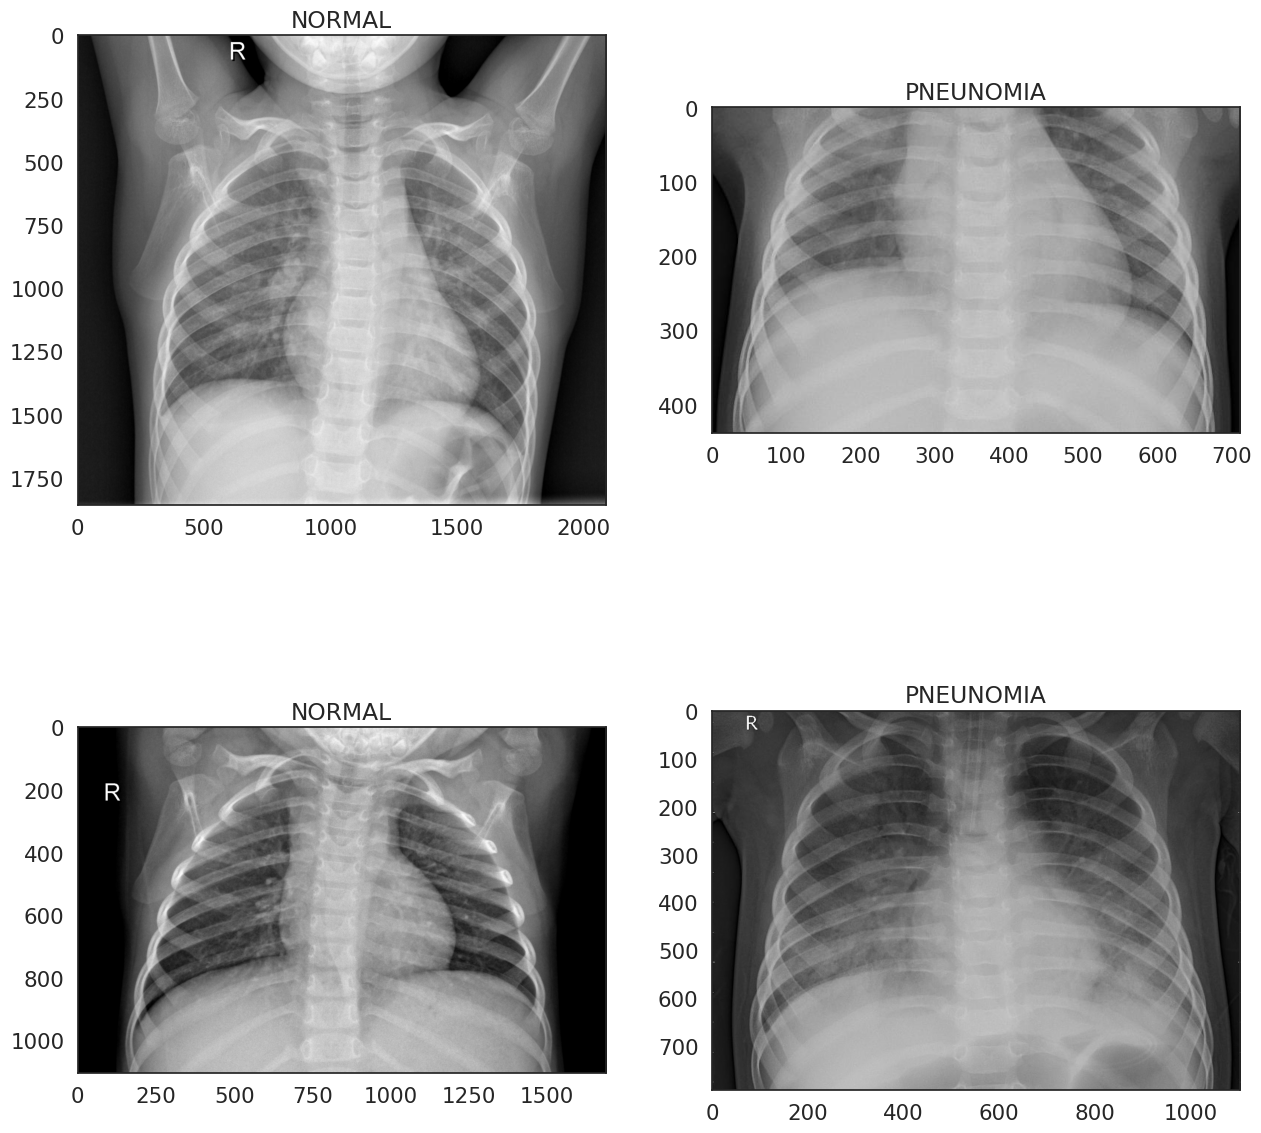

In [ ]:
fig, ax= plt.subplots(2,2, figsize=(15,15))

ax[0,0].imshow(image_normal1, cmap = "gray")
ax[0,0].set_title("NORMAL")

ax[0,1].imshow(image_pneumonia1, cmap = "gray")
ax[0,1].set_title("PNEUNOMIA")

ax[1,0].imshow(image_normal2, cmap = "gray")
ax[1,0].set_title("NORMAL")

ax[1,1].imshow(image_pneumonia2, cmap = "gray")
ax[1,1].set_title("PNEUNOMIA")

In [ ]:
# Training Set :
folder_normal = path + "/chest_xray/train/NORMAL/"
N_train_normal = len(os.listdir(folder_normal))


folder_pneunomia = path+"/chest_xray/train/PNEUMONIA/"
N_train_pneunomia = len(os.listdir(folder_pneunomia))


print(f"In the training set, we have {N_train_normal} normal and {N_train_pneunomia} pneumonia")

# Validation Set :
folder_normal = path+"/chest_xray/val/NORMAL/"
N_train_normal = len(os.listdir(folder_normal))



folder_pneunomia = path+"/chest_xray/val/PNEUMONIA/"
N_train_pneunomia = len(os.listdir(folder_pneunomia))
#print(os.listdir(folder_pneunomia))



print(f"In the validation set, we have {N_train_normal} normal and {N_train_pneunomia} pneumonia")

# Test Set :
folder_normal = path+"/chest_xray/test/NORMAL/"
N_train_normal = len(os.listdir(folder_normal))


folder_pneunomia = path+"/chest_xray/test/PNEUMONIA/"
N_train_pneunomia = len(os.listdir(folder_pneunomia))


print(f"In the test set, we have {N_train_normal} normal and {N_train_pneunomia} pneumonia")

In the training set, we have 1341 normal and 3875 pneumonia
In the validation set, we have 8 normal and 8 pneumonia
In the test set, we have 234 normal and 390 pneumonia


In [ ]:
train_transforms = transforms.Compose([
    transforms.Resize((224,224)), # transform the image in the same size
    #transforms.RandomHorizontalFlip(),
    transforms.ToTensor() # rescaling between 0 and 1 !
])

val_test_transfomes = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_dir = path+"/chest_xray/train"
#val_dir = "chest_xray/val"
test_dir = path+"/chest_xray/test"

train_data = ImageFolder(train_dir, train_transforms)
#val_data = ImageFolder(val_dir, val_test_transfomes)
test_data = ImageFolder(test_dir, val_test_transfomes)



In [ ]:
all_paths = [train_data.imgs[i][0] for i in range(len(train_data))]
all_labels = [train_data.imgs[i][1] for i in range(len(train_data))]
test_paths = [test_data.imgs[i][0] for i in range(len(test_data))]
test_label = [test_data.imgs[i][1] for i in range(len(test_data))]

print(all_paths)
print(all_labels)


['/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0115-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0117-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0119-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0122-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0125-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0127-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0128-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0129-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0131-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0133-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0135-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/IM-0137-0001.jpeg', '/kaggle/input/chest-xray-pneumonia/che

In [ ]:
print(train_data.class_to_idx)
num_classes = len(train_data.class_to_idx)
print(num_classes)


{'NORMAL': 0, 'PNEUMONIA': 1}
2


In [ ]:
train_path, val_path, train_label, val_label = train_test_split(
    all_paths,
    all_labels,
    test_size = 0.2,
    stratify = all_labels,
    random_state=42
)

print(f"Train : {len(train_label)}, Val : {len(val_label)}")

Train : 4172, Val : 1044


In [ ]:
print("Training Set : ")
print(f"Normal : {train_label.count(0)}")
print(f"Pneumonia : {train_label.count(1)}")

print("\nVal Set : ")
print(f"Normal : {val_label.count(0)}")
print(f"Pneumonia : {val_label.count(1)}")

print("\nTest Set : ")
print(f"Normal : {val_label.count(0)}")
print(f"Pneumonia : {val_label.count(1)}")

Training Set : 
Normal : 1073
Pneumonia : 3099

Val Set : 
Normal : 268
Pneumonia : 776

Test Set : 
Normal : 268
Pneumonia : 776


In [ ]:
class XRayDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("L") # 1 channel grey color
        label = self.labels[idx]

        if self.transform:
            img = self.transform(img)

        label = torch.tensor(label, dtype=torch.long)

        return img, label


In [ ]:
train_data = XRayDataset(train_path, train_label, transform=train_transforms)
val_data =  XRayDataset(val_path, val_label, transform=val_test_transfomes)
test_data = XRayDataset(test_paths, test_label, transform=val_test_transfomes)

In [ ]:
BATCH_SIZE = 64
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True )
val_loader = DataLoader(val_data, batch_size = BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

In [ ]:
for xb, yb in train_loader:
    print(f"Features batch size : {xb.shape}")
    print(f"Labels batch size : {yb.shape}")
    break

Features batch size : torch.Size([64, 1, 224, 224])
Labels batch size : torch.Size([64])


In [ ]:
for xb, yb in test_loader:
    print(f"Features batch size : {xb.shape}")
    print(f"Labels batch size : {yb.shape}")
    break

Features batch size : torch.Size([64, 1, 224, 224])
Labels batch size : torch.Size([64])


In [ ]:
# Weighted loss

targets = np.array(train_label)
class_counts = np.bincount(targets)  # [n_normal, n_pneumonia]
N = len(targets)
K = len(class_counts)
print(N)
print(K)

class_weights = N / (K * class_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print("class_counts:", class_counts)
print("class_weights:", class_weights)




4172
2
class_counts: [1073 3099]
class_weights: tensor([1.9441, 0.6731], device='cuda:0')


In [ ]:
LEARNING_RATE = 1e-3
EPOCHS = 100
PATIENCE = 10

DROPOUT_RATE = 0.3
L1_LAMBDA = 0
L2_LAMBDA = 0.001

# Weighted loss
criterion = nn.CrossEntropyLoss(weight = class_weights)

print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rare:", LEARNING_RATE)
print("Dropout Rate:", DROPOUT_RATE)
print("L1 Penalty:", L1_LAMBDA)
print("L2 Penalty:", L2_LAMBDA)

Epochs: 100
Batch Size: 64
Learning Rare: 0.001
Dropout Rate: 0.3
L1 Penalty: 0
L2 Penalty: 0.001


In [ ]:
# CNN Architecture parameters
# Number of convolutional blocks
NUM_BLOCKS = 4

# Number of conv layers per block
CONVS_PER_BLOCK = 1

# Use strided convolutions instead of pooling
USE_STRIDE = False

# Stride value when USE_STRIDE is True
STRIDE_VALUE = 2

# Padding size
PADDING_SIZE = 1

# Pooling size when USE_STRIDE is False
POOL_SIZE = 2

# Number of channels in first block
INITIAL_CHANNELS = 32

# Channel multiplication factor between blocks
CHANNEL_MULTIPLIER = 2

print("Num Blocks:", NUM_BLOCKS)
print("Convs per Block:", CONVS_PER_BLOCK)
print("Use Stride:", USE_STRIDE)
print("Stride Value:", STRIDE_VALUE)
print("Padding Size:", PADDING_SIZE)
print("Pool Size:", POOL_SIZE)
print("Initial Channels:", INITIAL_CHANNELS)
print("Channel Multiplier:", CHANNEL_MULTIPLIER)

Num Blocks: 2
Convs per Block: 1
Use Stride: False
Stride Value: 2
Padding Size: 1
Pool Size: 2
Initial Channels: 32
Channel Multiplier: 2


In [ ]:
# Single convolutional block with multiple conv layers, ReLU and pooling/stride
class VanillaCNNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, num_convs=1, use_stride=False, stride_value=2, padding_size=1, pool_size=2):
        super().__init__()

        layers = []

        # First convolution: in_channels -> out_channels
        if num_convs == 1:
            # Single conv: apply stride here if use_stride is True
            stride = stride_value if use_stride else 1
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=padding_size, stride=stride))
        else:
            # Multiple convs: first one always has stride=1
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, stride=1))

            # Intermediate convolutions (all with stride=1)
            for i in range(1, num_convs - 1):
                layers.append(nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, stride=1))

            # Last convolution: apply stride here if use_stride is True
            stride = stride_value if use_stride else 1
            layers.append(nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=padding_size, stride=stride))

        # ReLU activation
        layers.append(nn.ReLU())

        # Pooling only if not using stride for spatial reduction
        if not use_stride:
            layers.append(nn.MaxPool2d(kernel_size=pool_size, stride=pool_size))

        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


# Convolutional Neural Network architecture for CIFAR10 classification
class CNN(nn.Module):
    def __init__(self, input_shape=(1,224,224), num_classes=2, dropout_rate=DROPOUT_RATE,
                 num_blocks=NUM_BLOCKS, convs_per_block=CONVS_PER_BLOCK,
                 use_stride=USE_STRIDE, stride_value=STRIDE_VALUE, padding_size=PADDING_SIZE, pool_size=POOL_SIZE,
                 initial_channels=INITIAL_CHANNELS, channel_multiplier=CHANNEL_MULTIPLIER): # if use_stride = False --> max pooling
        super().__init__()

        # Build convolutional blocks
        blocks = []
        in_channels = input_shape[0]
        out_channels = initial_channels

        for i in range(num_blocks):
            blocks.append(VanillaCNNBlock(
                in_channels=in_channels,
                out_channels=out_channels,
                num_convs=convs_per_block,
                use_stride=use_stride,
                stride_value=stride_value,
                padding_size=padding_size,
                pool_size=pool_size
            ))

            # Prepare for next block: increase channels
            in_channels = out_channels
            out_channels = out_channels * channel_multiplier

        self.features = nn.Sequential(*blocks)

        # Calculate flattened size after all blocks using a dummy forward pass
        # This approach is robust and works with any configuration of padding, stride, and pooling
        with torch.no_grad():
            dummy_input = torch.zeros(1, *input_shape)
            dummy_output = self.features(dummy_input)
            flattened_size = dummy_output.view(1, -1).shape[1]

        # Classification head: flatten features and apply dropout before final layer
        self.classifier_head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout_rate),
            nn.Linear(flattened_size, num_classes)
        )

    # Forward pass through the network
    def forward(self, x):
        x = self.features(x)
        x = self.classifier_head(x)
        return x

In [ ]:
SEED = 42

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

PyTorch version: 2.9.0+cu126
Device: cuda


In [ ]:
input_shape = (1,224,224)

In [ ]:
# Instantiate CNN model and move to computing device (CPU/GPU)
cnn_model = CNN(
    input_shape,
    num_classes,
    num_blocks=NUM_BLOCKS,
    convs_per_block=CONVS_PER_BLOCK,
    use_stride=USE_STRIDE,
    stride_value=STRIDE_VALUE,
    padding_size=PADDING_SIZE,
    pool_size=POOL_SIZE,
    initial_channels=INITIAL_CHANNELS,
    channel_multiplier=CHANNEL_MULTIPLIER
    ).to(device)

# Display model architecture summary
summary(cnn_model, input_size=input_shape)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 224, 224]             320
              ReLU-2         [-1, 32, 224, 224]               0
         MaxPool2d-3         [-1, 32, 112, 112]               0
   VanillaCNNBlock-4         [-1, 32, 112, 112]               0
            Conv2d-5         [-1, 64, 112, 112]          18,496
              ReLU-6         [-1, 64, 112, 112]               0
         MaxPool2d-7           [-1, 64, 56, 56]               0
   VanillaCNNBlock-8           [-1, 64, 56, 56]               0
           Flatten-9               [-1, 200704]               0
          Dropout-10               [-1, 200704]               0
           Linear-11                    [-1, 2]         401,410
Total params: 420,226
Trainable params: 420,226
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.19
Forward/

In [ ]:
# Set up TensorBoard logging and save model architecture
experiment_name = "pneumonia_cnn"
writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
x = torch.randn(1, input_shape[0], input_shape[1], input_shape[2]).to(device)
writer.add_graph(cnn_model, x)

# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(cnn_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [ ]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [ ]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [ ]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

In [ ]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "models/"+experiment_name+'_model.pt')

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

In [ ]:
%%time
# Train model and track training history
cnn_model, training_history = fit(
    model=cnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    criterion=criterion,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    writer=writer,
    verbose=1,
    experiment_name="cnn_5",
    patience=PATIENCE
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = cnn_model
    best_performance = training_history['val_f1'][-1]

Training 100 epochs...
Epoch   1/100 | Train: Loss=1.4529, F1 Score=0.6587 | Val: Loss=0.2576, F1 Score=0.9329
Epoch   2/100 | Train: Loss=0.1771, F1 Score=0.9308 | Val: Loss=0.1215, F1 Score=0.9411
Epoch   3/100 | Train: Loss=0.1123, F1 Score=0.9590 | Val: Loss=0.0958, F1 Score=0.9639
Epoch   4/100 | Train: Loss=0.1170, F1 Score=0.9574 | Val: Loss=0.1360, F1 Score=0.9681
Epoch   5/100 | Train: Loss=0.0961, F1 Score=0.9649 | Val: Loss=0.1432, F1 Score=0.9624
Epoch   6/100 | Train: Loss=0.0888, F1 Score=0.9661 | Val: Loss=0.0916, F1 Score=0.9714
Epoch   7/100 | Train: Loss=0.0777, F1 Score=0.9718 | Val: Loss=0.0804, F1 Score=0.9705
Epoch   8/100 | Train: Loss=0.0652, F1 Score=0.9760 | Val: Loss=0.1215, F1 Score=0.9721
Epoch   9/100 | Train: Loss=0.0535, F1 Score=0.9812 | Val: Loss=0.0828, F1 Score=0.9743
Epoch  10/100 | Train: Loss=0.0475, F1 Score=0.9814 | Val: Loss=0.0872, F1 Score=0.9733
Epoch  11/100 | Train: Loss=0.0479, F1 Score=0.9802 | Val: Loss=0.0877, F1 Score=0.9670
Epoch  12

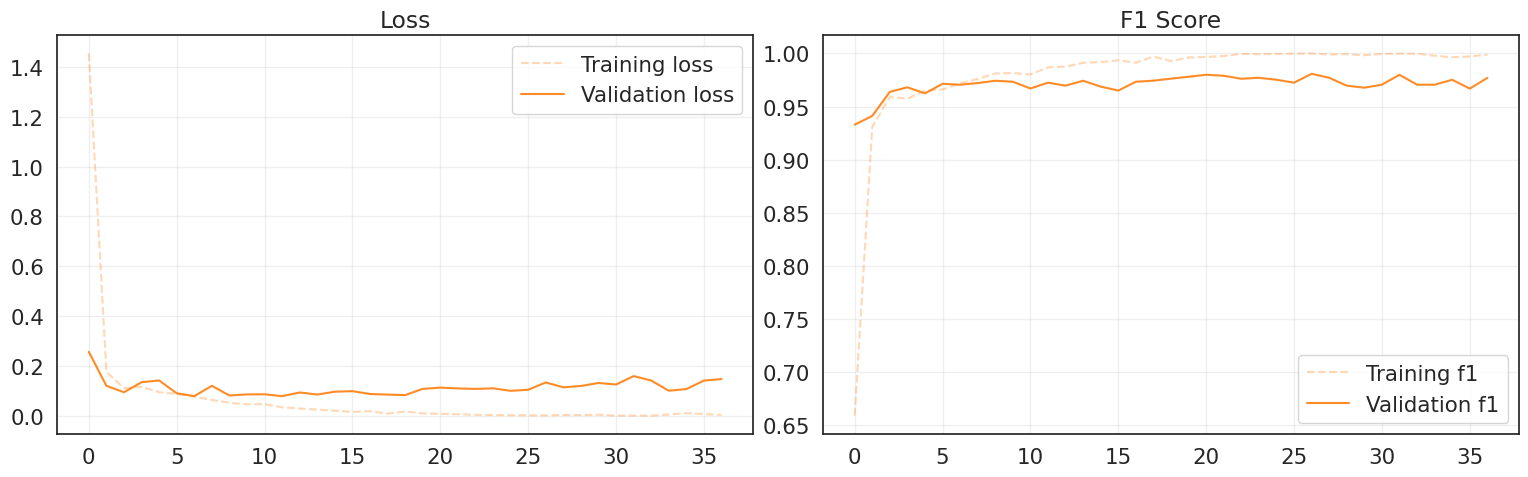

In [ ]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

Accuracy over the validation set: 0.9808
Precision over the validation set: 0.9808
Recall over the validation set: 0.9808
F1 score over the validation set: 0.9808


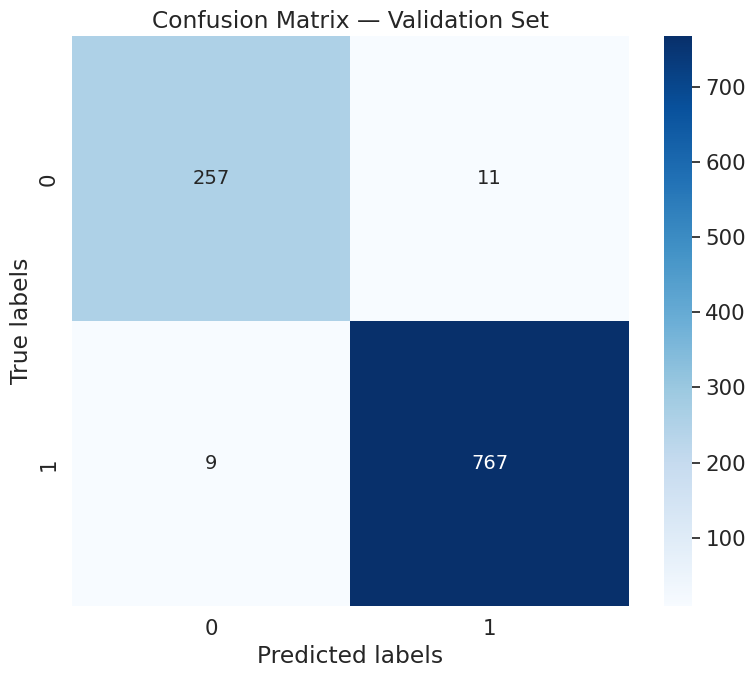

In [ ]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = cnn_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

# Inference on the test set

In [ ]:
# Collect predictions and ground truth labels
test_preds, test_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in test_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = best_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        test_preds.append(preds)
        test_targets.append(yb.numpy())

# Combine all batches into single arrays
test_preds = np.concatenate(test_preds)
test_targets = np.concatenate(test_targets)

Accuracy over the test set: 0.7244
Precision over the test set: 0.8033
Recall over the test set: 0.7244
F1 score over the test set: 0.6704


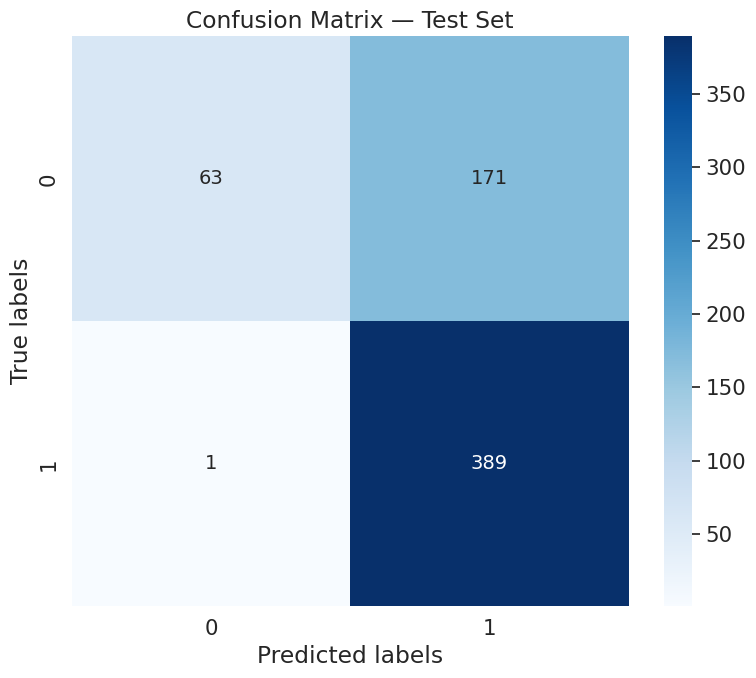

In [ ]:
# Calculate overall test accuracy
test_acc = accuracy_score(test_targets, test_preds)
test_prec = precision_score(test_targets, test_preds, average='weighted')
test_rec = recall_score(test_targets, test_preds, average='weighted')
test_f1 = f1_score(test_targets, test_preds, average='weighted')
print(f"Accuracy over the test set: {test_acc:.4f}")
print(f"Precision over the test set: {test_prec:.4f}")
print(f"Recall over the test set: {test_rec:.4f}")
print(f"F1 score over the test set: {test_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(test_targets, test_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Test Set')
plt.tight_layout()
plt.show()